In [3]:
import pandas as pd
df = pd.read_csv('../data/german_credit.csv')
print(df.head())
print(df.shape)
print(df['Class'].value_counts(normalize=True))

                status  duration                            credit_history  \
0         ... < 100 DM         6   critical account/other credits existing   
1    0 <= ... < 200 DM        48  existing credits paid back duly till now   
2  no checking account        12   critical account/other credits existing   
3         ... < 100 DM        42  existing credits paid back duly till now   
4         ... < 100 DM        24           delay in paying off in the past   

               purpose  amount                     savings  \
0  domestic appliances    1169  unknown/no savings account   
1  domestic appliances    5951                ... < 100 DM   
2           retraining    2096                ... < 100 DM   
3     radio/television    7882                ... < 100 DM   
4            car (new)    4870                ... < 100 DM   

  employment_duration  installment_rate                  personal_status_sex  \
0      ... >= 7 years                 4                        male : single  

KeyError: 'Class'

In [4]:
print("=== БАЛАНС КЛАССОВ ===")
print(df['credit_risk'].value_counts(normalize=True))

print("\n=== ПРОПУСКИ ===")
print(df.isnull().sum().sum(), "всего пропусков в датасете")

print("\n=== ТИПЫ ДАННЫХ ===")
print(df.dtypes.value_counts())

=== БАЛАНС КЛАССОВ ===
credit_risk
1    0.7
0    0.3
Name: proportion, dtype: float64

=== ПРОПУСКИ ===
0 всего пропусков в датасете

=== ТИПЫ ДАННЫХ ===
object    13
int64      8
Name: count, dtype: int64


C:\Users\ACER\AppData\Local\Temp\ipykernel_11908\622426232.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='credit_risk', palette='Set2')
C:\Users\ACER\AppData\Local\Temp\ipykernel_11908\622426232.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='credit_risk', y='duration', palette='Set2')


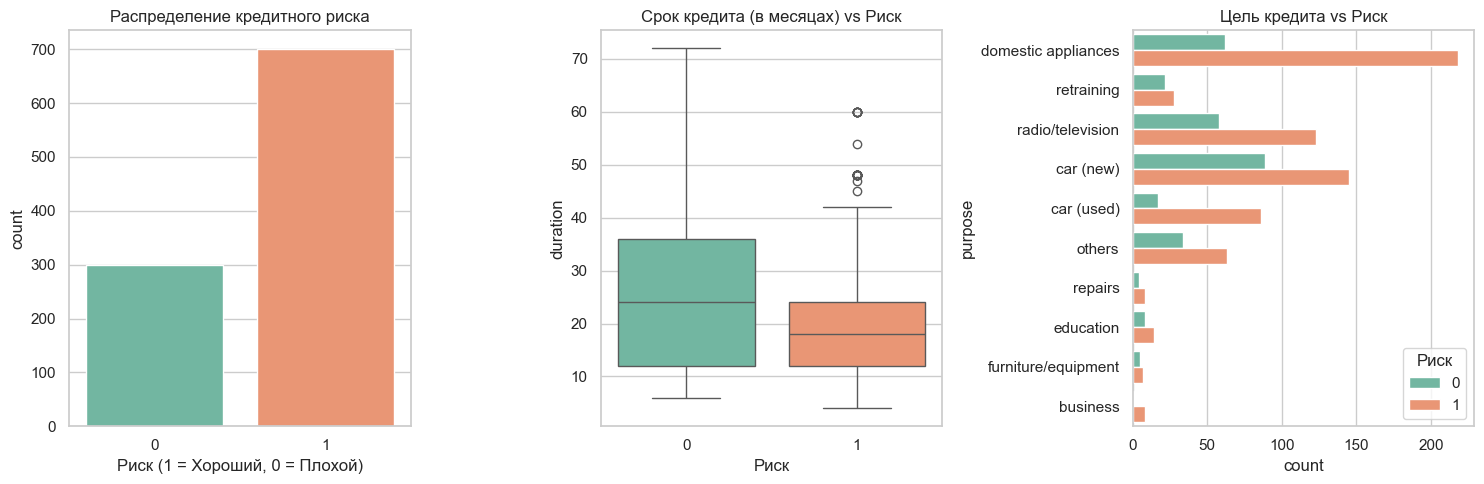

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.countplot(data=df, x='credit_risk', palette='Set2')
plt.title('Распределение кредитного риска')
plt.xlabel('Риск (1 = Хороший, 0 = Плохой)')

plt.subplot(1, 3, 2)
sns.boxplot(data=df, x='credit_risk', y='duration', palette='Set2')
plt.title('Срок кредита (в месяцах) vs Риск')
plt.xlabel('Риск')

plt.subplot(1, 3, 3)
sns.countplot(data=df, y='purpose', hue='credit_risk', palette='Set2')
plt.title('Цель кредита vs Риск')
plt.legend(title='Риск', loc='lower right')

plt.tight_layout()
plt.show()

EDA: Дисбаланс классов составляет 70/30. Обнаружена сильная связь между сроком кредита и риском дефолта: у плохих заемщиков медианный срок кредита выше (24 мес против 18 мес), а также больше выбросов. По целям кредитования выделяются бизнес и подержанные авто — там доля дефолтов визуально выше.

In [6]:
from sklearn.model_selection import train_test_split

X = df.drop('credit_risk', axis=1)
y = df['credit_risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Размер трейна:", X_train.shape)
print("Размер теста:", X_test.shape)

Размер трейна: (800, 20)
Размер теста: (200, 20)


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, drop_first=True)

X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

print(f"Колонок до кодирования: {X_train.shape[1]}")
print(f"Колонок после кодирования: {X_train_encoded.shape[1]}")

model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train_encoded, y_train)

proba_lr = model_lr.predict_proba(X_test_encoded)[:, 1]

print(f"ROC-AUC на тесте: {roc_auc_score(y_test, proba_lr):.4f}")

Колонок до кодирования: 20
Колонок после кодирования: 48
ROC-AUC на тесте: 0.7533


C:\Users\ACER\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)  # Внимание: только transform!

model_lr_scaled = LogisticRegression(max_iter=1000, random_state=42)
model_lr_scaled.fit(X_train_scaled, y_train)

proba_lr_scaled = model_lr_scaled.predict_proba(X_test_scaled)[:, 1]
print(f"ROC-AUC (со StandardScaler): {roc_auc_score(y_test, proba_lr_scaled):.4f}")
from catboost import CatBoostClassifier

cat_features_indices = X_train.select_dtypes(include=['object']).columns.tolist()

model_cb = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    random_seed=42,
    verbose=100 
)

model_cb.fit(X_train, y_train, cat_features=cat_features_indices)

proba_cb = model_cb.predict_proba(X_test)[:, 1]
print(f"ROC-AUC (CatBoost): {roc_auc_score(y_test, proba_cb):.4f}")

ROC-AUC (со StandardScaler): 0.7514
0:	learn: 0.6742040	total: 199ms	remaining: 1m 39s
100:	learn: 0.3535823	total: 3.05s	remaining: 12.1s
200:	learn: 0.2477405	total: 6.08s	remaining: 9.05s
300:	learn: 0.1898337	total: 9.09s	remaining: 6.01s
400:	learn: 0.1448112	total: 12.1s	remaining: 2.99s
499:	learn: 0.1140001	total: 15.1s	remaining: 0us
ROC-AUC (CatBoost): 0.7719


In [10]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import numpy as np

pred_cb = model_cb.predict(X_test) 

print("=== МАТРИЦА ОШИБОК (Порог 0.5) ===")
print(confusion_matrix(y_test, pred_cb))
print(f"Precision: {precision_score(y_test, pred_cb):.4f}")
print(f"Recall: {recall_score(y_test, pred_cb):.4f}")
print(f"F1-score: {f1_score(y_test, pred_cb):.4f}")

from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_test, proba_cb)

mask = recall[:-1] >= 0.8
if mask.any():
    idx = np.argmax(mask)
    best_threshold = thresholds[idx]

    pred_custom = (proba_cb >= best_threshold).astype(int)
    
    print(f"\n=== ПОРОГ ДЛЯ RECALL >= 0.8 (Порог {best_threshold:.2f}) ===")
    print(confusion_matrix(y_test, pred_custom))
    print(f"Precision: {precision_score(y_test, pred_custom):.4f}")
    print(f"Recall: {recall_score(y_test, pred_custom):.4f}")

=== МАТРИЦА ОШИБОК (Порог 0.5) ===
[[ 31  29]
 [ 15 125]]
Precision: 0.8117
Recall: 0.8929
F1-score: 0.8503

=== ПОРОГ ДЛЯ RECALL >= 0.8 (Порог 0.05) ===
[[  0  60]
 [  0 140]]
Precision: 0.7000
Recall: 1.0000


Снижение порога позволяет поймать больше дефолтов, но увеличивает число отказов надежным клиентам. Банку нужно выбрать баланс в зависимости от стоимости риска

Идеальный порог по F1: 0.54
Максимальный F1-score: 0.8522


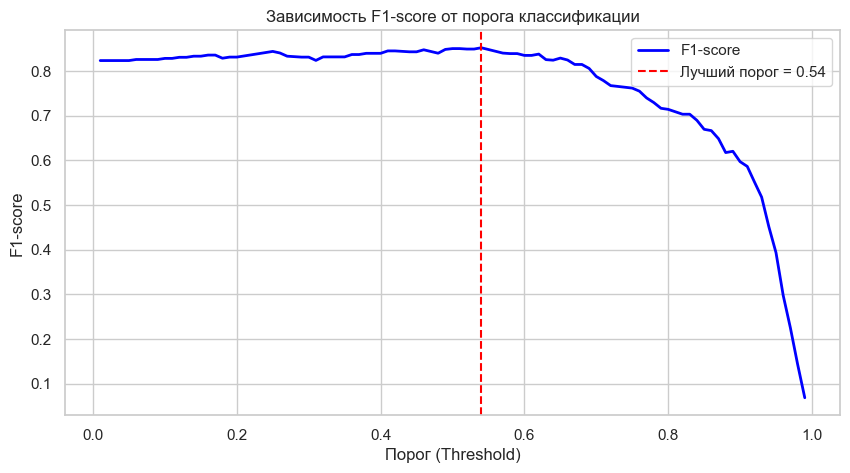

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

thresholds_to_test = np.arange(0.01, 1.0, 0.01)
f1_scores = []

for t in thresholds_to_test:
    preds = (proba_cb >= t).astype(int)
    f1_scores.append(f1_score(y_test, preds))

best_idx = np.argmax(f1_scores)
best_f1_threshold = thresholds_to_test[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Идеальный порог по F1: {best_f1_threshold:.2f}")
print(f"Максимальный F1-score: {best_f1:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(thresholds_to_test, f1_scores, label='F1-score', color='blue', linewidth=2)
plt.axvline(x=best_f1_threshold, color='red', linestyle='--', label=f'Лучший порог = {best_f1_threshold:.2f}')
plt.title('Зависимость F1-score от порога классификации')
plt.xlabel('Порог (Threshold)')
plt.ylabel('F1-score')
plt.legend()
plt.grid(True)
plt.show()